In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
df[["studytime", "failures", "absences", "G1", "G2", "G3"]].head()

,studytime,failures,absences,G1,G2,G3
0,2,0,6,5,6,6
1,2,0,4,5,5,6
2,2,3,10,7,8,10
3,3,0,2,15,14,15
4,2,0,4,6,10,10


In [4]:
X = df[["studytime", "failures", "absences", "G1", "G2"]].to_numpy(dtype=float)
y = df["G3"].to_numpy(dtype=float)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (395, 5)
y shape: (395,)


In [5]:
np.random.seed(42)

indices = np.random.permutation(len(y))
split_index = int(0.8 * len(y))

train_indices = indices[:split_index]
test_indices = indices[split_index:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))

Training samples: 316
Testing samples: 79


In [6]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

std[std == 0] = 1

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

print("Training means:", X_train_scaled.mean(axis=0))
print("Training standard deviations:", X_train_scaled.std(axis=0))

Training means: [-3.55508520e-17 -8.25640540e-17 -3.05662668e-17  1.66105262e-16
  8.43207360e-18]
Training standard deviations: [1. 1. 1. 1. 1.]


In [7]:
X_train_bias = np.column_stack(
    (np.ones(len(X_train_scaled)), X_train_scaled)
)

X_test_bias = np.column_stack(
    (np.ones(len(X_test_scaled)), X_test_scaled)
)

print("Training matrix shape:", X_train_bias.shape)
print("Testing matrix shape:", X_test_bias.shape)

Training matrix shape: (316, 6)
Testing matrix shape: (79, 6)


In [8]:
weights = np.zeros(X_train_bias.shape[1])

learning_rate = 0.01
epochs = 10000
n = len(y_train)

print("Initial weights:", weights)

Initial weights: [0. 0. 0. 0. 0. 0.]


In [9]:
loss_history = []

for epoch in range(epochs):
    predictions = X_train_bias @ weights

    errors = predictions - y_train

    gradients = (2 / n) * (X_train_bias.T @ errors)

    weights = weights - learning_rate * gradients

    loss = np.mean(errors ** 2)
    loss_history.append(loss)

print("Training completed!")
print("Final weights:", weights)
print("Final training MSE:", loss_history[-1])

Training completed!
Final weights: [10.42405063 -0.07010176 -0.16866265  0.31690018  0.59779491  3.67205286]
Final training MSE: 3.491360817077171


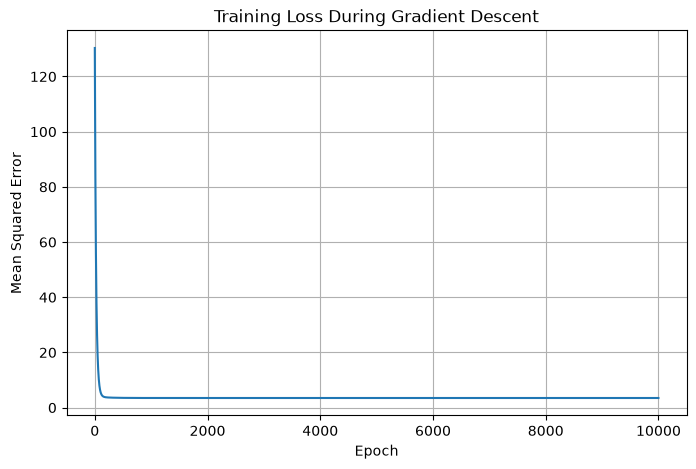

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training Loss During Gradient Descent")
plt.grid(True)
plt.show()

In [11]:
y_pred = X_test_bias @ weights

results = pd.DataFrame({
    "Actual Grade": y_test,
    "Predicted Grade": y_pred,
    "Absolute Error": np.abs(y_test - y_pred)
})

display(results.head(10))

,Actual Grade,Predicted Grade,Absolute Error
0,14.0,12.612434,1.387566
1,11.0,12.263756,1.263756
2,14.0,14.278382,0.278382
3,10.0,9.102638,0.897362
4,10.0,8.413655,1.586345
5,13.0,12.789493,0.210507
6,18.0,17.172864,0.827136
7,0.0,-0.949146,0.949146
8,10.0,9.279697,0.720303
9,7.0,7.340642,0.340642


In [12]:
mae = np.mean(np.abs(y_test - y_pred))

ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

r2 = 1 - (ss_res / ss_tot)

print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"R² Score: {r2:.3f}")

Mean Absolute Error (MAE): 1.159
R² Score: 0.776


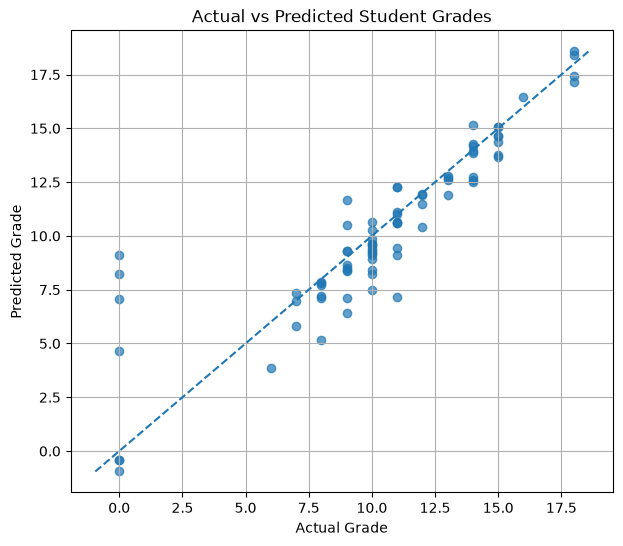

In [13]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Grade")
plt.ylabel("Predicted Grade")
plt.title("Actual vs Predicted Student Grades")
plt.grid(True)
plt.show()